# IS630: Green Light for an Indie Studio
## Notebook 07: Final Test Scoring
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> An AI coding assistant wrote the code in this notebook, following decisions the group made on 28 Oct 2026. Every code section is labelled with its provenance. All interpretations, evaluations of model performance and conclusions are written by group members in the designated cells.

This is the only notebook that loads the test holdout from notebook 00 (`data/interim/00_test_holdout.parquet`, 1,320 games never seen by notebooks 01 to 06). It scores one model on it, once.

**Group decisions (28 Oct 2026):**
1. The final model is the controllable model: notebook 04's reduced Bayesian model, the controllable model with the lower validation RMSE. No other model is scored. The training mean is reported beside it as the baseline every R² is measured against.
2. The model is scored as fitted in notebook 04, on the development split. After scoring, it is refitted on every game in scope, training and holdout together. The refit is the model to use from here on. It is not scored, because it has seen every game.
3. The notebook runs once. Re-running it after any upstream change means the test is no longer untouched, which has to be disclosed.

| Section | Content |
|---|---|
| 1 | Freeze the model before the holdout is loaded |
| 2 | Refit the development-split model and confirm it matches notebook 04 |
| 3 | Build the holdout with notebook 02's feature code |
| 4 | Score once, and compare test against validation |
| 5 | Refit on every game in scope |

**Reads:** `data/interim/00_train.parquet`, `data/interim/00_test_holdout.parquet`, `data/processed/02_train.parquet`, `data/processed/02_validation.parquet`, `data/processed/02_feature_spec.json`, `data/interim/04_aq3_importance.parquet`, `outputs/tables/04_aq3_reduced_vs_full.csv`, `outputs/tables/04_aq3_factor_map.csv`
**Writes:** `data/interim/07_test_predictions.parquet`, tables `outputs/tables/07_*.csv`, figures `outputs/figures/07_*.png`

## Setup
*Code: Generated by AI Assistant*

In [1]:
import sys
import json
import subprocess
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()) / "src"))
from is630 import config
from is630.features import build_features, apply_training_stats
from is630.models import COMPLETION_PRIORS, SAMPLE_KW, completion_model, completion_sample

for d in (config.FIGURES, config.TABLES):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
rng = np.random.default_rng(config.SEED)

def save_fig(fig, name):
    # Write a figure to outputs/figures at 300 dpi.
    fig.savefig(config.FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

def flat(trace, name):
    # Posterior draws with chains stacked: (draws, values).
    a = np.asarray(trace.posterior[name])
    return a.reshape(a.shape[0] * a.shape[1], -1)

df_train = pd.read_parquet(config.PROCESSED / "02_train.parquet")
df_val = pd.read_parquet(config.PROCESSED / "02_validation.parquet")
with open(config.PROCESSED / "02_feature_spec.json", encoding="utf-8") as f:
    feature_spec = json.load(f)
FEATURES = feature_spec["model_features"]
THRESHOLDS = {k: v for k, v in feature_spec["inclusion_thresholds"].items() if k.startswith("min_")}
importance = pd.read_parquet(config.INTERIM / "04_aq3_importance.parquet").set_index("feature")
labels = pd.read_csv(config.TABLES / "04_aq3_factor_map.csv", index_col=0)["label"]
print(f"rows in: {len(df_train):,} development training, {len(df_val):,} validation")
print(f"thresholds from notebook 02: {THRESHOLDS}")
print(f"pymc {pm.__version__}, arviz {az.__version__}")

g++ not available, if using conda: `conda install gxx`


rows in: 4,224 development training, 1,057 validation
thresholds from notebook 02: {'min_reviews_reception': 10, 'min_reviews_completion': 50, 'min_hltb_polls': 5}
pymc 6.3.2, arviz 1.3.0


## 1. Freeze the model
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this cell runs before the holdout is read. It writes down the model, its predictors, priors, sampler settings, seed and inclusion thresholds, the validation numbers from notebook 04 it will be compared against, and the git commit and working-tree state at the time. Anyone can then check that nothing was changed after the test results were seen.

In [2]:
KEPT = [f for f in FEATURES if importance.loc[f, "in_reduced_model"]]
val_04 = pd.read_csv(config.TABLES / "04_aq3_reduced_vs_full.csv", index_col=0)
MODEL = "Bayesian, reduced"
assert val_04.loc[MODEL, "predictors"] == len(KEPT)

git = lambda *a: subprocess.run(["git", *a], cwd=config.ROOT, capture_output=True, text=True).stdout.strip()
frozen = pd.Series({
    "model": "notebook 04 reduced (controllable) Bayesian hierarchical model on the log completion ratio",
    "fitted_on": "development split (02_train), as in notebook 04",
    "predictors": len(KEPT),
    "predictor_list": ", ".join(KEPT),
    "priors": json.dumps(COMPLETION_PRIORS),
    "sampler": json.dumps({k: v for k, v in SAMPLE_KW.items() if k != "progressbar"}),
    "seed": config.SEED,
    "thresholds": json.dumps(THRESHOLDS),
    "final_refit": "same model on every game in scope after scoring, not scored; if it misses a convergence threshold, "
                   "re-sampled once with twice the draws and tuning",
    "validation_games": int(val_04.loc[MODEL, "validation_games"]),
    "validation_RMSE": val_04.loc[MODEL, "RMSE"],
    "validation_R2_vs_baseline": val_04.loc[MODEL, "R2_vs_baseline"],
    "git_commit": git("rev-parse", "HEAD"),
    "uncommitted_changes": git("status", "--porcelain") or "none",
    "frozen_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}, name="value")
frozen.to_csv(config.TABLES / "07_frozen_choices.csv")
frozen.to_frame()

,value
model,notebook 04 reduced (controllable) Bayesian hi...
fitted_on,"development split (02_train), as in notebook 04"
predictors,16
predictor_list,"feature_log_achievements, flag_has_achievement..."
priors,"{""intercept"": 1.0, ""beta"": 0.5, ""sigma_dev"": 0..."
sampler,"{""draws"": 1000, ""tune"": 1000, ""chains"": 4, ""ta..."
seed,42
thresholds,"{""min_reviews_reception"": 10, ""min_reviews_com..."
final_refit,same model on every game in scope after scorin...
validation_games,482


## 2. The development-split model
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the frozen model is refitted exactly as in notebook 04, on the development split with the same seed, so its validation numbers can be recomputed here with the same code that scores the test set. The check below confirms the fit reproduces notebook 04's validation RMSE.

In [3]:
s = completion_sample(df_train, df_val, FEATURES)
with completion_model(s.X_train[KEPT], s.y_train, s.dev_train, s.inv_polls_train, len(s.dev_levels), COMPLETION_PRIORS):
    idata = pm.sample(**SAMPLE_KW)

GLOBAL = ["intercept", "beta", "sigma", "tau", "sigma_dev"]

def diagnostics(trace):
    g = az.summary(trace, var_names=GLOBAL)
    z = az.summary(trace, var_names=["z_dev"])
    checks = pd.Series({
        "max r_hat (global)": float(g["r_hat"].max()), "max r_hat (developer z)": float(z["r_hat"].max()),
        "min ess_bulk (global)": float(g["ess_bulk"].min()), "min ess_tail (global)": float(g["ess_tail"].min()),
        "min ess_bulk (developer z)": float(z["ess_bulk"].min()),
        "divergences": int(np.asarray(trace.sample_stats["diverging"]).sum()),
    })
    passed = (checks["max r_hat (global)"] < 1.01 and checks["max r_hat (developer z)"] < 1.01
              and checks["min ess_bulk (global)"] > 400 and checks["min ess_tail (global)"] > 400 and checks["divergences"] == 0)
    return g, checks, passed

dev_summary, dev_checks, dev_ok = diagnostics(idata)
print(dev_checks.round(3).to_string())
print(f"thresholds: r_hat < 1.01, ess_bulk and ess_tail > 400, zero divergences -> {'all met' if dev_ok else 'NOT MET'}")
assert dev_ok, "the frozen model did not converge, so it is not scored"
print(f"\nrows: {len(s.y_train):,} development training, {len(s.y_val):,} validation (completion model sample)")

NUTS[numpyro]: [intercept, beta, sigma_dev, z_dev, sigma, tau]


C:\Users\leesi\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


max r_hat (global)               1.008
max r_hat (developer z)          1.008
min ess_bulk (global)          788.247
min ess_tail (global)         1317.347
min ess_bulk (developer z)    5654.008
divergences                      0.000
thresholds: r_hat < 1.01, ess_bulk and ess_tail > 400, zero divergences -> all met

rows: 1,927 development training, 482 validation (completion model sample)


In [4]:
def predict(trace, X, dev, inv_polls):
    """Posterior mean log ratio (seen developers get their effect, unseen get 0)
    and a 90% posterior predictive interval with the poll-dependent noise, as in notebook 03."""
    d = {k: flat(trace, k) for k in ["intercept", "beta", "sigma", "tau", "sigma_dev", "z_dev"]}
    u = d["sigma_dev"] * d["z_dev"]
    u_x = np.where(dev >= 0, u[:, np.clip(dev, 0, None)], 0.0)
    mu = d["intercept"] + d["beta"] @ X.to_numpy().T + u_x
    noise = np.sqrt(d["sigma"] ** 2 + d["tau"] ** 2 * inv_polls[None, :])
    pp = mu + rng.standard_normal(mu.shape) * noise
    return mu.mean(0), np.quantile(pp, 0.05, axis=0), np.quantile(pp, 0.95, axis=0)

BASELINE = s.y_train.mean()   # development-training mean, as in notebooks 03 and 04

def prediction_frame(frame, X, y, dev, inv_polls):
    mu, low, high = predict(idata, X[KEPT], dev, inv_polls)
    return pd.DataFrame({
        "steam_appid": frame["steam_appid"].to_numpy(), "steam_name": frame["steam_name"].to_numpy(),
        "developer_group": frame["developer_group"].to_numpy(), "developer_seen": dev >= 0,
        "observed": y, "baseline": BASELINE, "model": mu, "model_low": low, "model_high": high,
    })

val_preds = prediction_frame(s.val, s.X_val, s.y_val, s.dev_val, s.inv_polls_val)
rmse_here = np.sqrt(np.mean((val_preds["observed"] - val_preds["model"]) ** 2))
print(f"validation RMSE here {rmse_here:.4f}, notebook 04 {frozen['validation_RMSE']:.4f}")
assert abs(rmse_here - frozen["validation_RMSE"]) < 1e-3, "the refit does not reproduce notebook 04"

validation RMSE here 1.0362, notebook 04 1.0362


### Interpretation: The development-split model
**Author**: 
<!-- State whether the refitted model converged by the printed thresholds and whether it reproduces notebook 04's validation RMSE, so the model being scored is the one the group chose. -->

## 3. Build the holdout
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the holdout goes through the same feature code as the training data (`build_features` and `apply_training_stats` in `src/is630/features.py`, moved out of notebook 02 for this purpose). Two steps use training data: each developer's count of games and the median used to fill a missing language count. Both come from the development split, the data the scored model was fitted on, so no holdout value feeds into its own features. Continuous predictors are standardised with development-training means and SDs. Holdout games by a developer seen in training get that developer's effect; the rest get zero, as in validation.

In [5]:
raw_test = pd.read_parquet(config.INTERIM / "00_test_holdout.parquet")
config.verify_appid_fingerprint(raw_test, config.TEST_APPID_SHA256, "test holdout")
raw_train = pd.read_parquet(config.INTERIM / "00_train.parquet")
assert set(raw_test["steam_appid"]).isdisjoint(raw_train["steam_appid"]), "holdout overlaps training"

test = apply_training_stats(build_features(raw_test, **THRESHOLDS), df_train)
t = completion_sample(df_train, test, FEATURES)
pd.testing.assert_frame_equal(t.X_train, s.X_train)   # same standardisation and developer index as the scored model
print(f"rows in: {len(raw_test):,} holdout games")
print(f"rows out of the feature build (software, missing review counts, negative prices dropped): {len(test):,}")
print(f"rows out (completion model sample, the thresholds above): {len(t.val):,}")
print(f"holdout games whose developer appears in development training: {(t.dev_val >= 0).sum():,} ({(t.dev_val >= 0).mean() * 100:.1f}%)")

target = pd.DataFrame({
    "development training": pd.Series(s.y_train).describe(percentiles=[0.05, 0.5, 0.95]),
    "validation": pd.Series(s.y_val).describe(percentiles=[0.05, 0.5, 0.95]),
    "test": pd.Series(t.y_val).describe(percentiles=[0.05, 0.5, 0.95]),
}).T
target["median_polls"] = [s.train["hltb_main_story_polled"].median(), s.val["hltb_main_story_polled"].median(),
                          t.val["hltb_main_story_polled"].median()]
target["developer_seen_share"] = [np.nan, (s.dev_val >= 0).mean(), (t.dev_val >= 0).mean()]
target.round(3)

rows in: 1,320 holdout games
rows out of the feature build (software, missing review counts, negative prices dropped): 1,320
rows out (completion model sample, the thresholds above): 672
holdout games whose developer appears in development training: 291 (43.3%)


,count,mean,std,min,5%,50%,95%,max,median_polls,developer_seen_share
development training,1927.0,-0.386,1.088,-6.516,-2.203,-0.238,1.145,3.283,27.0,NaN
validation,482.0,-0.369,1.122,-5.704,-2.436,-0.172,0.932,4.535,23.0,0.446
test,672.0,-0.345,1.066,-5.659,-2.313,-0.161,1.098,2.947,26.0,0.433


### Interpretation: The holdout sample
**Author**: 
<!-- Report how many holdout games reach the completion model and how that compares with validation. Compare the log ratio distribution, poll counts and the share of games by a developer seen in training across the three samples, and say whether the test set looks like the data the model was built on. -->

## 4. Score once
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the frozen model is scored on the holdout with the metrics of notebook 03: RMSE, MAE, R² against the baseline (the development-training mean), typical factor error (exp of the median absolute error on the log scale), and the coverage and width of the 90% predictive interval. Validation is scored with the same code, so the two columns are directly comparable. A developer-level bootstrap (2,000 resamples of developers) gives an interval for the model's RMSE gain over the baseline.

In [6]:
test_preds = prediction_frame(t.val, t.X_val, t.y_val, t.dev_val, t.inv_polls_val)

def score(p):
    err, base_err = p["observed"] - p["model"], p["observed"] - p["baseline"]
    return {"games": len(p), "RMSE": np.sqrt(np.mean(err ** 2)), "baseline_RMSE": np.sqrt(np.mean(base_err ** 2)),
            "MAE": np.mean(np.abs(err)), "R2_vs_baseline": 1 - np.sum(err ** 2) / np.sum(base_err ** 2),
            "typical_factor_error": np.exp(np.median(np.abs(err))),
            "coverage_90": np.mean((p["observed"] >= p["model_low"]) & (p["observed"] <= p["model_high"])),
            "mean_interval_width": np.mean(p["model_high"] - p["model_low"])}

def bootstrap_gain(p, B=2000):
    # Resample developers, not games: games by one developer are not independent.
    sq = pd.DataFrame({"model": (p["observed"] - p["model"]) ** 2, "baseline": (p["observed"] - p["baseline"]) ** 2,
                       "dev": p["developer_group"].to_numpy()}).groupby("dev").agg(["sum", "count"])
    m, b, n = sq[("model", "sum")].to_numpy(), sq[("baseline", "sum")].to_numpy(), sq[("model", "count")].to_numpy()
    gains = []
    for _ in range(B):
        i = rng.integers(0, len(n), len(n))
        gains.append(np.sqrt(m[i].sum() / n[i].sum()) - np.sqrt(b[i].sum() / n[i].sum()))
    return {"developers": len(n), "rmse_gain_2.5%": np.quantile(gains, 0.025), "rmse_gain_97.5%": np.quantile(gains, 0.975),
            "share_of_resamples_below_0": np.mean(np.array(gains) < 0)}

scores = pd.DataFrame({name: {**score(p), "rmse_gain": score(p)["RMSE"] - score(p)["baseline_RMSE"], **bootstrap_gain(p)}
                       for name, p in [("validation", val_preds), ("test", test_preds)]}).T
scores.loc["test - validation"] = scores.loc["test"] - scores.loc["validation"]
scores.loc["test - validation", ["games", "developers"]] = np.nan
scores.to_csv(config.TABLES / "07_test_vs_validation.csv")
scores.loc[["test"]].to_csv(config.TABLES / "07_test_completion_scores.csv")
print("A negative RMSE gain means the model has lower error than the baseline.")
scores.T.round(4)

A negative RMSE gain means the model has lower error than the baseline.


,validation,test,test - validation
games,482.0000,672.0000,NaN
RMSE,1.0362,0.9752,-0.0610
baseline_RMSE,1.1210,1.0660,-0.0551
MAE,0.7469,0.7075,-0.0393
R2_vs_baseline,0.1456,0.1631,0.0174
typical_factor_error,1.7477,1.6780,-0.0697
coverage_90,0.8921,0.8943,0.0022
mean_interval_width,3.1045,3.0739,-0.0307
rmse_gain,-0.0848,-0.0908,-0.0059
developers,414.0000,542.0000,NaN


### Interpretation: Test scores (AQ2)
**Author**: 
<!-- This is the final answer on predictive performance. Using the test column and its bootstrap interval, say whether the controllable model predicts the completion ratio better than the baseline on games it has never seen, and by how much in RMSE and typical factor error. Compare each test metric with its validation value, including the 90% interval coverage, and report any drop as it is. Do not refit or change anything in response. -->

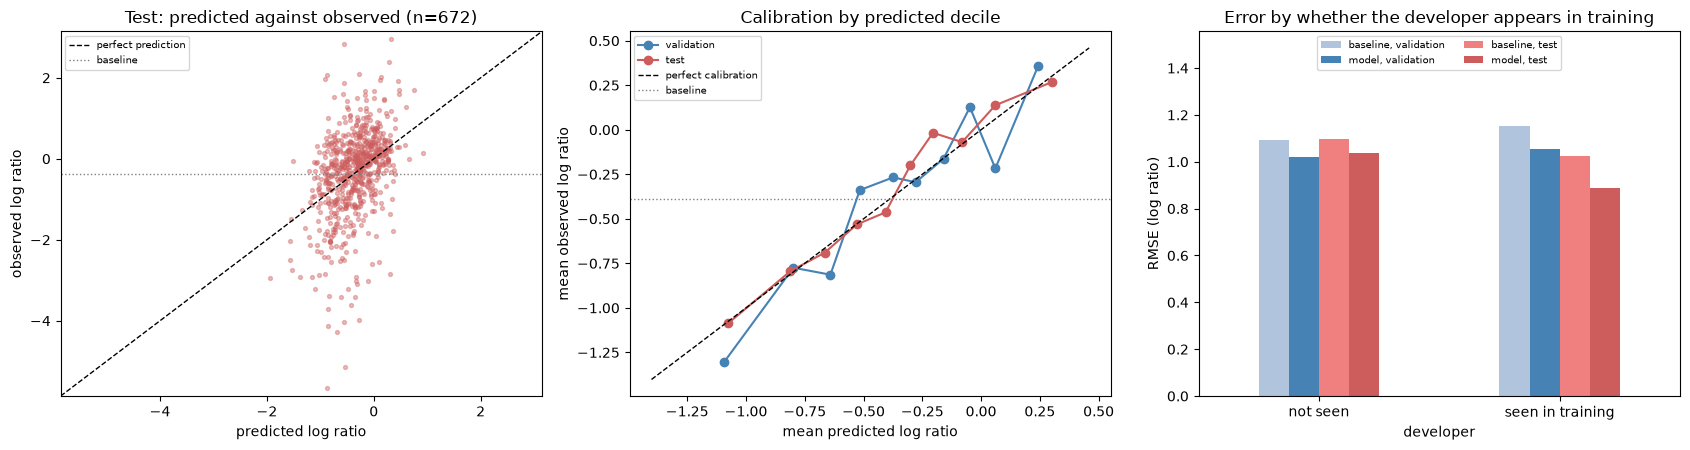

,sample,developer,games,model,baseline
0,validation,not seen,267,1.0221,1.0944
1,validation,seen in training,215,1.0534,1.1532
2,test,not seen,381,1.0365,1.0962
3,test,seen in training,291,0.8885,1.0251


In [7]:
rows = []
for name, p in [("validation", val_preds), ("test", test_preds)]:
    decile = pd.qcut(p["model"], 10, labels=False, duplicates="drop")
    rows.append(p.groupby(decile).agg(games=("observed", "size"), mean_predicted=("model", "mean"),
                                      mean_observed=("observed", "mean")).assign(sample=name))
calibration = pd.concat(rows).rename_axis("decile").reset_index()
calibration.to_csv(config.TABLES / "07_test_calibration.csv", index=False)

by_seen = pd.DataFrame([{"sample": name, "developer": "seen in training" if seen else "not seen",
                         "games": len(g), "model": np.sqrt(np.mean((g["observed"] - g["model"]) ** 2)),
                         "baseline": np.sqrt(np.mean((g["observed"] - g["baseline"]) ** 2))}
                        for name, p in [("validation", val_preds), ("test", test_preds)]
                        for seen, g in p.groupby("developer_seen")])
by_seen.to_csv(config.TABLES / "07_test_by_developer_seen.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
lims = [test_preds["observed"].min() - 0.2, test_preds["observed"].max() + 0.2]
axes[0].scatter(test_preds["model"], test_preds["observed"], s=8, alpha=0.4, color="indianred")
axes[0].plot(lims, lims, color="black", linestyle="--", linewidth=1, label="perfect prediction")
axes[0].axhline(BASELINE, color="grey", linestyle=":", linewidth=1, label="baseline")
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("predicted log ratio"); axes[0].set_ylabel("observed log ratio")
axes[0].set_title(f"Test: predicted against observed (n={len(test_preds):,})"); axes[0].legend(fontsize=7)

for (name, g), colour in zip(calibration.groupby("sample", sort=False), ["steelblue", "indianred"]):
    axes[1].plot(g["mean_predicted"], g["mean_observed"], marker="o", color=colour, label=name)
lo = calibration[["mean_predicted", "mean_observed"]].min().min() - 0.1
hi = calibration[["mean_predicted", "mean_observed"]].max().max() + 0.1
axes[1].plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=1, label="perfect calibration")
axes[1].axhline(BASELINE, color="grey", linestyle=":", linewidth=1, label="baseline")
axes[1].set_xlabel("mean predicted log ratio"); axes[1].set_ylabel("mean observed log ratio")
axes[1].set_title("Calibration by predicted decile"); axes[1].legend(fontsize=7)

pivot = by_seen.pivot(index="developer", columns="sample", values=["baseline", "model"])
pivot.columns = [f"{m}, {smp}" for m, smp in pivot.columns]
pivot[["baseline, validation", "model, validation", "baseline, test", "model, test"]].plot.bar(
    ax=axes[2], rot=0, color=["lightsteelblue", "steelblue", "lightcoral", "indianred"])
axes[2].set_ylabel("RMSE (log ratio)"); axes[2].set_xlabel("developer")
axes[2].set_title("Error by whether the developer appears in training")
axes[2].set_ylim(0, by_seen[["model", "baseline"]].max().max() * 1.35); axes[2].legend(fontsize=7, ncol=2, loc="upper center")
plt.tight_layout()
save_fig(fig, "07_test_vs_validation")
plt.show()
by_seen.round(4)

### Interpretation: Calibration and error by developer
**Author**: 
<!-- Say whether the model's predictions on the test set match the observed log ratio across the deciles, and where they over- or under-predict, compared with validation. Compare the error for games by developers seen in training with the rest, in both samples. -->

In [8]:
test_preds.to_parquet(config.INTERIM / "07_test_predictions.parquet", index=False)
print(f"rows out: {len(test_preds):,} test predictions -> data/interim/07_test_predictions.parquet")

rows out: 672 test predictions -> data/interim/07_test_predictions.parquet


## 5. Refit on every game in scope
*Code: Generated by AI Assistant*

*Written by AI Assistant*: with the test score recorded, the same model (same predictors, priors and sampler settings) is refitted on every game in scope: development training, validation and the holdout together. The feature build starts again from the notebook 00 tables, so developer game counts, the language median and the standardisation all come from the full set. If the refit misses a convergence threshold, it is re-sampled once with twice the draws and tuning, a rule fixed in section 1 before the holdout was loaded; the model itself does not change. This refit is the final model. It is not scored: it has seen every game, so any error measured on them would be in-sample. Section 4's test numbers are the performance estimate.

In [9]:
everything = build_features(pd.concat([raw_train, raw_test], ignore_index=True), **THRESHOLDS)
everything = apply_training_stats(everything, everything)
a = completion_sample(everything, everything, FEATURES)
print(f"rows in: {len(raw_train) + len(raw_test):,} games in scope; rows out (completion model sample): {len(a.y_train):,} "
      f"= {len(s.y_train):,} development + {len(s.y_val):,} validation + {len(t.y_val):,} test")
assert len(a.y_train) == len(s.y_train) + len(s.y_val) + len(t.y_val)

with completion_model(a.X_train[KEPT], a.y_train, a.dev_train, a.inv_polls_train, len(a.dev_levels), COMPLETION_PRIORS):
    idata_all = pm.sample(**SAMPLE_KW)
all_summary, all_checks, all_ok = diagnostics(idata_all)
if not all_ok:
    # Rule fixed in section 1 before the holdout was loaded: one re-sample with twice the draws and tuning
    print(all_checks.round(3).to_string())
    print("thresholds not met -> re-sampling once with twice the draws and tuning, model unchanged\n")
    with completion_model(a.X_train[KEPT], a.y_train, a.dev_train, a.inv_polls_train, len(a.dev_levels), COMPLETION_PRIORS):
        idata_all = pm.sample(**{**SAMPLE_KW, "draws": 2 * SAMPLE_KW["draws"], "tune": 2 * SAMPLE_KW["tune"]})
    all_summary, all_checks, all_ok = diagnostics(idata_all)
print(all_checks.round(3).to_string())
print(f"thresholds: r_hat < 1.01, ess_bulk and ess_tail > 400, zero divergences -> {'all met' if all_ok else 'NOT MET'}")

NUTS[numpyro]: [intercept, beta, sigma_dev, z_dev, sigma, tau]


rows in: 6,601 games in scope; rows out (completion model sample): 3,081 = 1,927 development + 482 validation + 672 test


max r_hat (global)               1.002
max r_hat (developer z)          1.009
min ess_bulk (global)          929.943
min ess_tail (global)         1534.842
min ess_bulk (developer z)    6154.290
divergences                      0.000
thresholds: r_hat < 1.01, ess_bulk and ess_tail > 400, zero divergences -> all met


### Interpretation: Convergence of the final refit
**Author**: 
<!-- State whether the refit on every game converged by the printed thresholds. A refit that did not converge cannot be used as the final model. -->

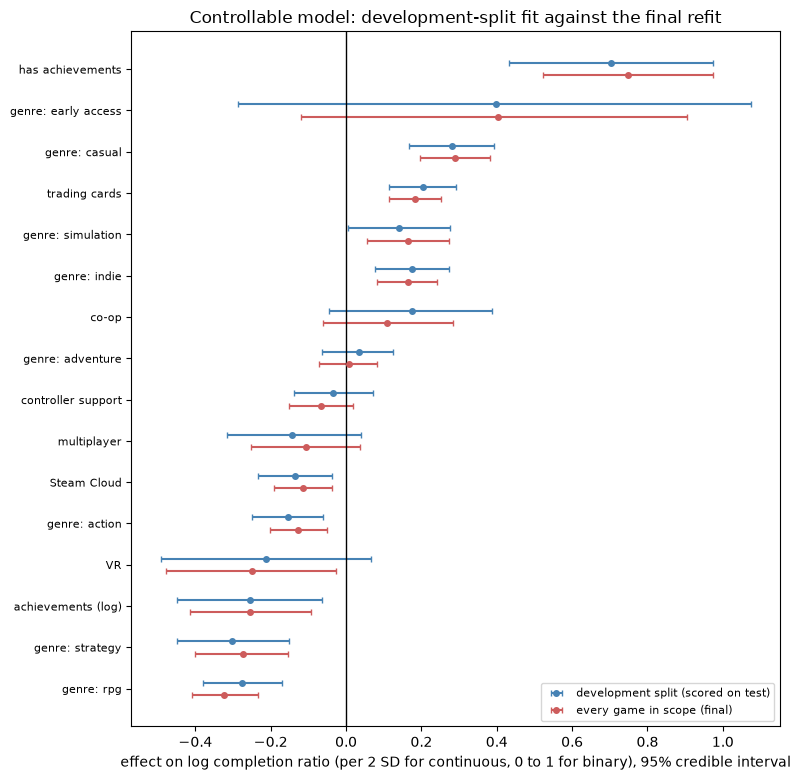

intervals excluding 0: development split 10, final 11 of 16


,label,unit,final_mean,final_low,final_high,final_multiplier,final_excludes_0,development_mean,development_low,development_high
feature,,,,,,,,,,
feature_log_achievements,achievements (log),per 2 SD,-0.254,-0.414,-0.092,0.776,True,-0.255,-0.449,-0.064
flag_has_achievements,has achievements,0 to 1,0.748,0.522,0.973,2.113,True,0.702,0.433,0.973
cat_multiplayer,multiplayer,0 to 1,-0.105,-0.251,0.038,0.900,False,-0.144,-0.317,0.040
cat_coop,co-op,0 to 1,0.108,-0.062,0.285,1.115,False,0.175,-0.044,0.388
cat_controller,controller support,0 to 1,-0.067,-0.153,0.018,0.936,False,-0.034,-0.138,0.071
cat_steam_cloud,Steam Cloud,0 to 1,-0.115,-0.193,-0.037,0.892,True,-0.135,-0.233,-0.038
cat_trading_cards,trading cards,0 to 1,0.183,0.113,0.251,1.201,True,0.204,0.114,0.293
cat_vr,VR,0 to 1,-0.251,-0.477,-0.026,0.778,True,-0.213,-0.491,0.066
genre_indie,genre: indie,0 to 1,0.163,0.082,0.242,1.177,True,0.174,0.076,0.273


In [10]:
# Effects on the scale of notebook 04: per 2 SD for continuous predictors, 0 to 1 for binary
def effects(trace, sample):
    per = np.array([2.0 if f in sample.continuous else 1.0 for f in KEPT])
    b = flat(trace, "beta") * per
    return pd.DataFrame({"mean": b.mean(0), "low": np.quantile(b, 0.025, axis=0), "high": np.quantile(b, 0.975, axis=0)}, index=KEPT)

dev_eff, all_eff = effects(idata, s), effects(idata_all, a)
final = pd.DataFrame({
    "label": labels.reindex(KEPT).to_numpy(),
    "unit": ["per 2 SD" if f in a.continuous else "0 to 1" for f in KEPT],
    "final_mean": all_eff["mean"], "final_low": all_eff["low"], "final_high": all_eff["high"],
    "final_multiplier": np.exp(all_eff["mean"]),
    "final_excludes_0": (all_eff["low"] > 0) | (all_eff["high"] < 0),
    "development_mean": dev_eff["mean"], "development_low": dev_eff["low"], "development_high": dev_eff["high"],
    "centre": a.centre.reindex(KEPT), "scale": a.scale.reindex(KEPT),   # to standardise a new game's continuous values
}, index=pd.Index(KEPT, name="feature"))
final.to_csv(config.TABLES / "07_final_model_effects.csv")
pd.concat({"final (every game)": all_summary.loc[["intercept", "sigma", "tau", "sigma_dev"]],
           "development split": dev_summary.loc[["intercept", "sigma", "tau", "sigma_dev"]]}).to_csv(
    config.TABLES / "07_final_model_parameters.csv")

order = final["final_mean"].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 0.4 * len(order) + 1.5))
for col, off, colour, lab in [("development", 0.15, "steelblue", "development split (scored on test)"),
                              ("final", -0.15, "indianred", "every game in scope (final)")]:
    m = final.loc[order, f"{col}_mean"]
    ax.errorbar(m, y + off, xerr=[m - final.loc[order, f"{col}_low"], final.loc[order, f"{col}_high"] - m],
                fmt="o", markersize=4, capsize=2, color=colour, label=lab)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(final.loc[order, "label"], fontsize=8)
ax.set_xlabel("effect on log completion ratio (per 2 SD for continuous, 0 to 1 for binary), 95% credible interval")
ax.set_title("Controllable model: development-split fit against the final refit"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
save_fig(fig, "07_final_model_effects")
plt.show()
print(f"intervals excluding 0: development split {int(((dev_eff['low'] > 0) | (dev_eff['high'] < 0)).sum())}, "
      f"final {int(final['final_excludes_0'].sum())} of {len(KEPT)}")
final.drop(columns=["centre", "scale"]).round(3)

### Interpretation: The final model
**Author**: 
<!-- Compare the final model's effects with the development-split fit that was scored: which effects kept their sign and size, which moved, and whether any interval now includes or excludes zero. Note that these estimates come from more games but have no test score of their own; the performance estimate is section 4's. -->

## Outputs
*Code: Generated by AI Assistant*

In [11]:
print(f"figures: {sorted(p.name for p in config.FIGURES.glob('07_*.png'))}")
print(f"tables : {sorted(p.name for p in config.TABLES.glob('07_*.csv'))}")

figures: ['07_final_model_effects.png', '07_test_vs_validation.png']
tables : ['07_final_model_effects.csv', '07_final_model_parameters.csv', '07_frozen_choices.csv', '07_test_by_developer_seen.csv', '07_test_calibration.csv', '07_test_completion_scores.csv', '07_test_vs_validation.csv']
